## Clasificación de alojamientos de Airbnb en Madrid mediante aprendizaje automático

### Introducción

Este proyecto compara tres modelos de clasificación (Naive Bayes gaussiano, KNN y árbol de decisión) para predecir el tipo de alojamiento (`room_type`) de un anuncio de Airbnb en Madrid a partir de características como el precio, la ubicación o la disponibilidad.

Para ello, se utiliza el archivo [`airbnb.csv`](airbnb.csv) contiene 13.321 anuncios y 11 variables. Es una versión adaptada con fines educativos del listado de anuncios de Madrid de abril de 2017, recopilado por [Inside Airbnb](https://insideairbnb.com/) a partir de información pública de Airbnb.

### Índice

- [Visualización de datos](#visualizacion-de-datos)
  - [Análisis descriptivo de la base de datos](#analisis-descriptivo)
  - [Variables cualitativas](#variables-cualitativas)
  - [Variables cuantitativas](#variables-cuantitativas)
- [Preprocesamiento de datos](#preprocesamiento-de-datos)
- [Evaluación de modelos](#evaluacion-de-modelos)
  - [Exactitud (Accuracy)](#exactitud)
  - [Matriz de confusión](#matriz-de-confusion)
- [Afinación de hiperparámetros](#afinacion-de-hiperparametros)
- [Conclusiones](#conclusiones)

Importamos todas las bibliotecas necesarias para llevar a cabo la actividad.

In [1]:
import os

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split, cross_val_score, cross_val_predict, GridSearchCV
from sklearn.preprocessing import OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.metrics import ConfusionMatrixDisplay
from sklearn.tree import DecisionTreeClassifier, plot_tree

Obtenemos la ruta del archivo `airbnb.csv` de forma independiente del sistema operativo, garantizando compatibilidad entre distintos entornos de ejecución.

In [2]:
PATH = os.path.join(
    os.getcwd(), "airbnb.csv"
)
PATH

'c:\\Users\\Antonio José\\Documents\\dev\\master\\aprendizaje-automatico\\bloque-1\\practica\\airbnb.csv'

In [3]:
data = pd.read_csv(PATH)

<a id="visualizacion-de-datos"></a>

### Visualización de datos

<a id="analisis-descriptivo"></a>

#### Análisis descriptivo de la base de datos

Realizamos una exploración inicial de la base de datos para conocer su estructura y las características de sus variables.

In [4]:
data

,neighbourhood_group,neighbourhood,latitude,longitude,room_type,price,minimum_nights,number_of_reviews,reviews_per_month,calculated_host_listings_count,availability_365
0,Centro,Justicia,40.424715,-3.698638,Entire home/apt,49,28,35,0.42,1,99
1,Centro,Embajadores,40.413418,-3.706838,Entire home/apt,80,5,18,0.30,1,188
2,Moncloa - Aravaca,Argüelles,40.424920,-3.713446,Entire home/apt,40,2,21,0.25,9,195
3,Moncloa - Aravaca,Casa de Campo,40.431027,-3.724586,Entire home/apt,55,2,3,0.13,9,334
4,Latina,Cármenes,40.403410,-3.740842,Private room,16,2,23,0.76,2,250
...,...,...,...,...,...,...,...,...,...,...,...
13316,Centro,Justicia,40.427500,-3.698354,Private room,14,1,0,0.00,1,10
13317,Chamberí,Gaztambide,40.431187,-3.711909,Entire home/apt,47,1,0,0.00,7,354
13318,Centro,Palacio,40.413552,-3.711461,Entire home/apt,60,2,0,0.00,1,17
13319,Centro,Universidad,40.425400,-3.709921,Entire home/apt,150,5,0,0.00,1,15


In [5]:
data.info()

<class 'pandas.DataFrame'>
RangeIndex: 13321 entries, 0 to 13320
Data columns (total 11 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   neighbourhood_group             13321 non-null  str    
 1   neighbourhood                   13321 non-null  str    
 2   latitude                        13321 non-null  float64
 3   longitude                       13321 non-null  float64
 4   room_type                       13321 non-null  str    
 5   price                           13321 non-null  int64  
 6   minimum_nights                  13321 non-null  int64  
 7   number_of_reviews               13321 non-null  int64  
 8   reviews_per_month               13321 non-null  float64
 9   calculated_host_listings_count  13321 non-null  int64  
 10  availability_365                13321 non-null  int64  
dtypes: float64(3), int64(5), str(3)
memory usage: 1.1 MB


La base de datos contiene 13.321 observaciones y 11 variables. No se aprecian valores nulos, ya que todas las columnas cuentan con 13.321 valores no nulos.

En cuanto al tipo de datos, las 11 variables de la base de datos se clasifican de la siguiente manera.

- Cadenas de texto (`str`) — `neighbourhood_group`, `neighbourhood`, `room_type`.
- Decimales (`float64`) — `latitude`, `longitude`, `reviews_per_month`.
- Enteros (`int64`) — `price`, `minimum_nights`, `number_of_reviews`, `calculated_host_listings_count`, `availability_365`.`

Cabe destacar que no hay variables de tipo fecha ni objetos complejos que requieran un tratamiento adicional, lo que simplifica el análisis posterior.

<a id="variables-cualitativas"></a>

#### Variables cualitativas

neighbourhood_group
Centro                   6773
Chamberí                  960
Salamanca                 883
Arganzuela                790
Tetuán                    463
Moncloa - Aravaca         450
Retiro                    439
Latina                    379
Chamartín                 361
Carabanchel               358
Ciudad Lineal             308
Puente de Vallecas        222
Hortaleza                 185
Fuencarral - El Pardo     170
Usera                     145
San Blas - Canillejas     117
Villaverde                 83
Barajas                    81
Moratalaz                  74
Villa de Vallecas          46
Vicálvaro                  34
Name: count, dtype: int64


<Axes: ylabel='neighbourhood_group'>

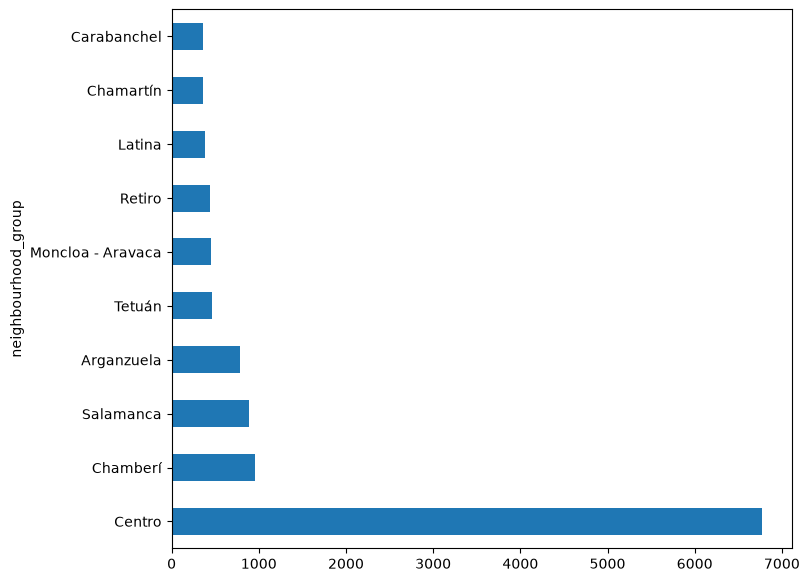

In [6]:
print(data["neighbourhood_group"].value_counts())
data["neighbourhood_group"].value_counts().head(10).plot(kind="barh", figsize=(8, 7))

En `neighbourhood_group`, Centro destaca por concentrar un número de alojamientos muy superior al resto de distritos. Aunque sea un valor atípico, resulta razonable en el contexto del alquiler turístico por su ubicación céntrica (valga la redundancia) y su atractivo para los visitantes.

neighbourhood
Embajadores       1848
Universidad       1363
Palacio           1084
Sol                942
Justicia           788
                  ... 
Pavones              4
El Goloso            4
Cuatro Vientos       3
Orcasitas            2
El Pardo             1
Name: count, Length: 126, dtype: int64


<Axes: ylabel='neighbourhood'>

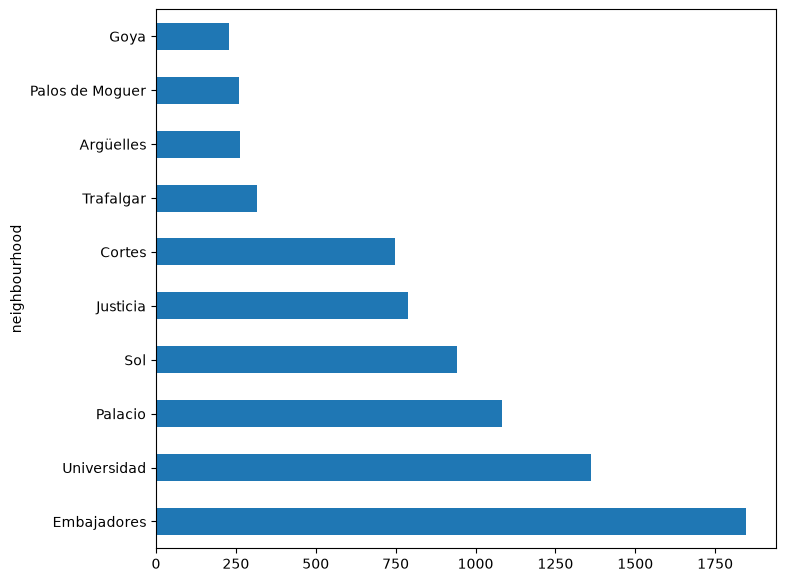

In [7]:
print(data["neighbourhood"].value_counts())
data["neighbourhood"].value_counts().head(10).plot(kind="barh", figsize=(8, 7))

En cuanto a `neighbourhood`, no hay ningún valor claramente atípico, aunque la distribución es desigual. Tiene sentido que barrios como Embajadores, Universidad y Palacio tengan más alojamientos, ya que están en el centro de Madrid, donde suele concentrarse el turismo.

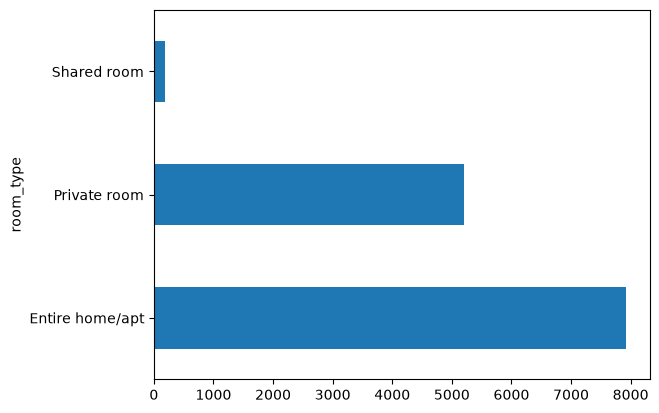

room_type
Entire home/apt    7926
Private room       5203
Shared room         192
Name: count, dtype: int64


In [8]:
data["room_type"].value_counts().plot(kind="barh")
plt.show()

print(data["room_type"].value_counts())

Dado que `room_type` es la variable que queremos predecir, conviene destacar el desequilibrio entre sus clases. La categoría `Shared room` cuenta con solo 192 registros, frente a los 7.926 de `Entire home/apt` y los 5.203 de `Private room`. Esta escasa representación puede dificultar que el modelo aprenda a identificarla y favorecer las predicciones de las clases mayoritarias.

<a id="variables-cuantitativas"></a>

#### Variables cuantitativas

In [9]:
data.describe()

,latitude,longitude,price,minimum_nights,number_of_reviews,reviews_per_month,calculated_host_listings_count,availability_365
count,13321.000000,13321.000000,13321.000000,13321.000000,13321.000000,13321.000000,13321.000000,13321.000000
mean,40.420730,-3.697268,69.171834,3.010885,22.986037,1.520329,7.605885,205.867202
std,0.020344,0.023832,103.721126,12.835619,38.406006,1.852367,19.619972,126.968961
min,40.331888,-3.863907,9.000000,1.000000,0.000000,0.000000,1.000000,0.000000
25%,40.410090,-3.707856,31.000000,1.000000,1.000000,0.110000,1.000000,84.000000
50%,40.418731,-3.701602,53.000000,2.000000,7.000000,0.780000,2.000000,247.000000
75%,40.427997,-3.693818,80.000000,3.000000,28.000000,2.320000,4.000000,321.000000
max,40.562736,-3.526821,7700.000000,1125.000000,446.000000,17.210000,145.000000,365.000000


`latitude` y `longitude` presentan valores coherentes, compatibles con la ubicación de Madrid y su entorno.

En cuanto a `price`, la media es de 69,17 y la mediana de 53. El tercer cuartil se sitúa en 80, lo que indica que al menos el 75 % de los alojamientos tiene un precio igual o inferior a ese valor. Frente a estas cifras, el máximo de 7.700 destaca como un posible valor atípico.

En `minimum_nights`, la estancia mínima exigida tiene una media de aproximadamente 3 noches y una mediana de 2. Además, el 75 % de los alojamientos exige como máximo 3 noches. Por ello, el máximo de 1.125 noches resulta especialmente llamativo y otro posible valor atípico que debería revisarse.

En las variables relacionadas con las reseñas se observa bastante variabilidad. Aunque los máximos se alejan de los valores habituales, son cifras plausibles que pueden reflejar diferencias en la antigüedad de los anuncios, su popularidad o la frecuencia de las estancias, por lo que no implican necesariamente errores en los datos.

`calculated_host_listings_count` presenta una mediana de 2, frente a una media de 7,61 y un máximo de 145, lo que apunta a la presencia de anfitriones que gestionan numerosos anuncios.

Por último, `availability_365` oscila entre 0 y 365 días, un rango coherente con la variable, y presenta una mediana de 247 días. No obstante, una disponibilidad de cero no permite concluir por sí sola que el alojamiento esté ocupado todo el año, ya que también puede deberse a fechas bloqueadas por el anfitrión.

latitude                             Axes(0.125,0.747241;0.133621x0.132759)
longitude                         Axes(0.285345,0.747241;0.133621x0.132759)
price                              Axes(0.44569,0.747241;0.133621x0.132759)
minimum_nights                    Axes(0.606034,0.747241;0.133621x0.132759)
number_of_reviews                 Axes(0.766379,0.747241;0.133621x0.132759)
reviews_per_month                    Axes(0.125,0.587931;0.133621x0.132759)
calculated_host_listings_count    Axes(0.285345,0.587931;0.133621x0.132759)
availability_365                   Axes(0.44569,0.587931;0.133621x0.132759)
dtype: object

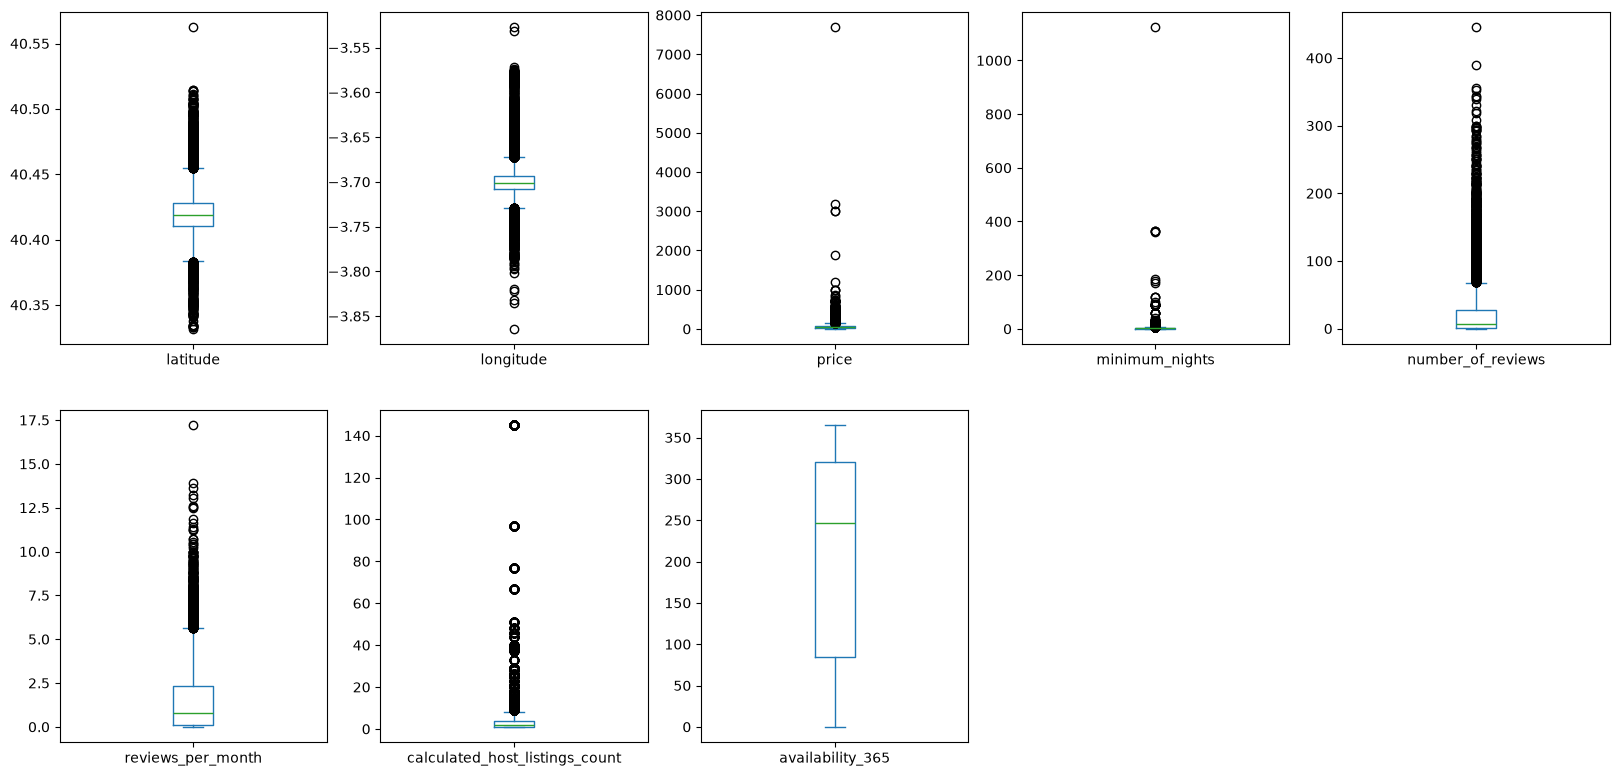

In [10]:
data.select_dtypes(include="number").plot(
    kind="box",
    subplots=True,
    layout=(5, 5),
    figsize=(20, 25)
)

Los diagramas de caja muestran numerosos valores atípicos, aunque disponemos de 13.321 registros. Iremos estudiando los aspectos mencionados anteriormente mediante histogramas.

array([[<Axes: title={'center': 'latitude'}>,
        <Axes: title={'center': 'longitude'}>,
        <Axes: title={'center': 'price'}>],
       [<Axes: title={'center': 'minimum_nights'}>,
        <Axes: title={'center': 'number_of_reviews'}>,
        <Axes: title={'center': 'reviews_per_month'}>],
       [<Axes: title={'center': 'calculated_host_listings_count'}>,
        <Axes: title={'center': 'availability_365'}>, <Axes: >]],
      dtype=object)

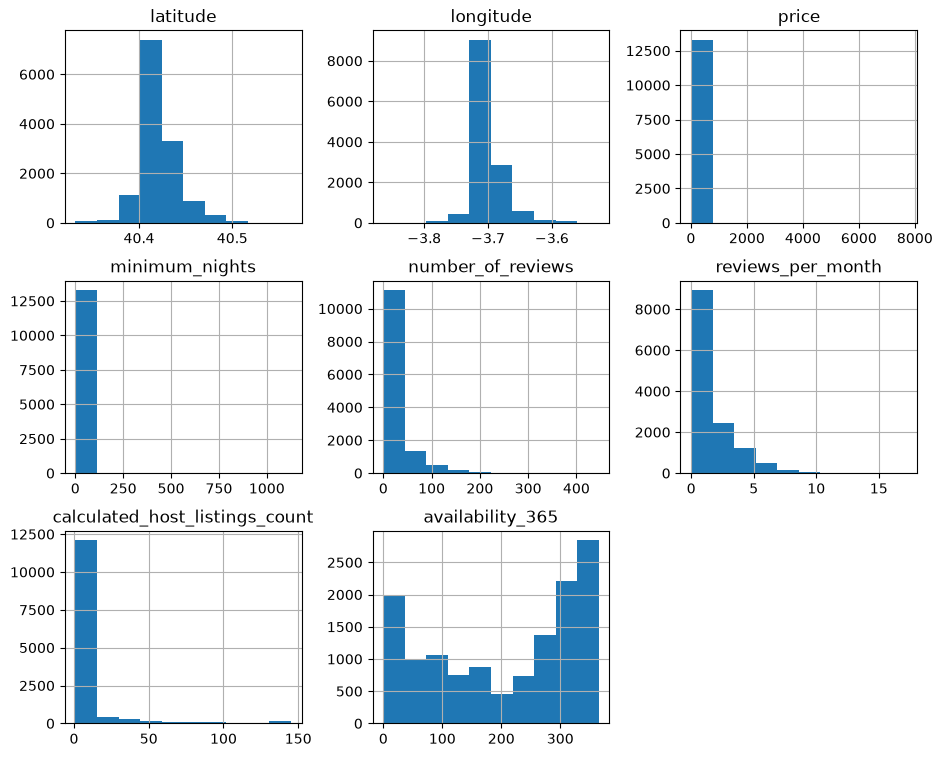

In [11]:
data.hist(figsize=(11, 9))

`latitude`, `longitude` y `availability_365` presentan distribuciones que parecen adecuadas, mientras que las demás variables muestran asimetría hacia la derecha. Los valores extremos amplían la escala del eje X y concentran las barras a la izquierda. Estudiaremos con más detalle los casos que más llaman la atención: `price`, `minimum_nights` y `number_of_reviews`.

<Axes: >

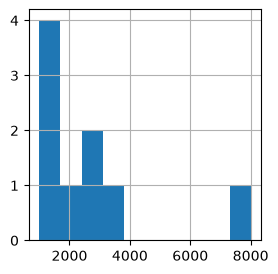

In [12]:
data["price"].hist(figsize=(3, 3), range=(1000, 8000))

En los precios entre 1.000 y 8.000, se observan pocos alojamientos con valores atípicos elevados, entre los que destaca el precio máximo de 7.700 por estar especialmente alejado del resto.

<Axes: >

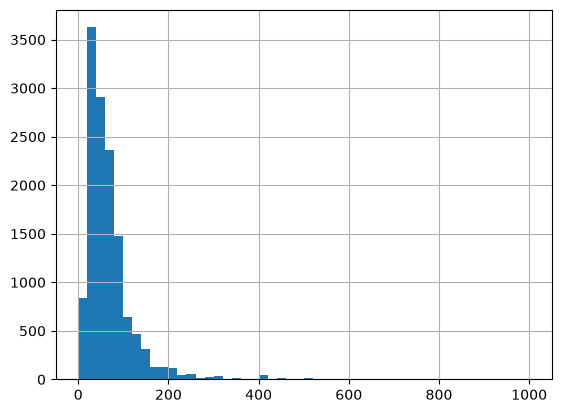

In [13]:
data["price"].hist(bins=50, range=(0, 1000))

Zoom hacia el intervalo de 0 a 1.000 para ver mejor cómo se distribuyen los precios habituales. La mayoría se concentra por debajo de 200.

<Axes: >

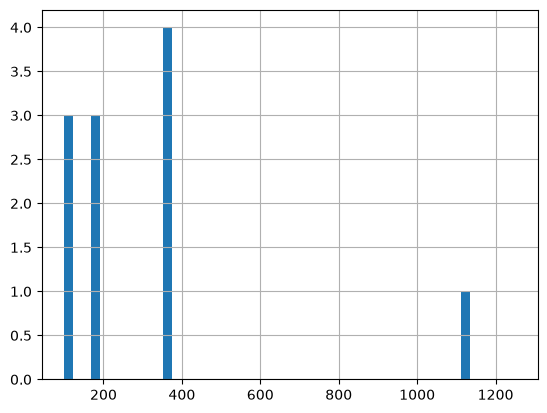

In [14]:
data["minimum_nights"].hist(bins=50, range=(100, 1250))

Los alojamientos con estancias mínimas entre 100 y 1.250 noches presentan valores atípicos muy superiores a los habituales. También nos encontramos con el máximo de 1.125 noches, especialmente alejado del resto.

<Axes: >

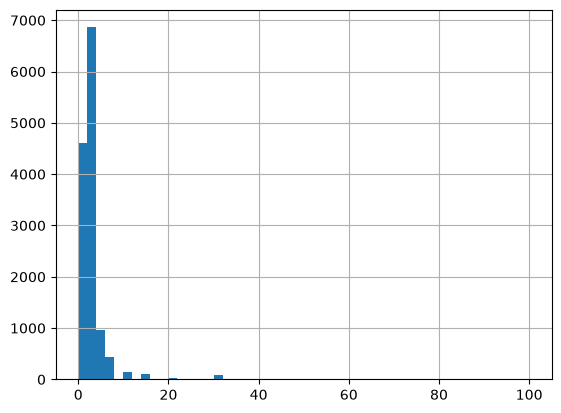

In [15]:
data["minimum_nights"].hist(bins=50, range=(0, 100))

Zoom hacia el intervalo de 0 a 100 noches para ver mejor cómo se distribuyen las estancias mínimas habituales. La mayoría se concentra en pocas noches.

<Axes: >

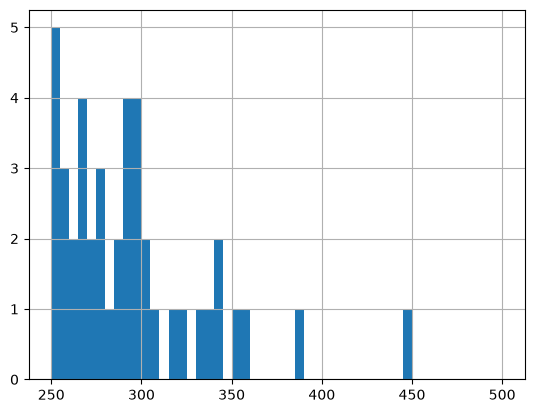

In [16]:
data["number_of_reviews"].hist(bins=50, range=(250, 500))

Entre 250 y 500 reseñas, la frecuencia disminuye conforme aumenta el número de reseñas y nos encontramos con el máximo de 446. Aunque son valores elevados respecto a los habituales, pueden corresponder a alojamientos populares o con mayor antigüedad y no implican necesariamente errores.

In [17]:
data.select_dtypes(include="number").corr()

,latitude,longitude,price,minimum_nights,number_of_reviews,reviews_per_month,calculated_host_listings_count,availability_365
latitude,1.000000,0.230304,0.067039,-0.006643,-0.065644,-0.074515,0.006747,0.037240
longitude,0.230304,1.000000,-0.027859,-0.001292,-0.034922,-0.001742,-0.042298,-0.001541
price,0.067039,-0.027859,1.000000,0.013118,-0.036391,-0.060191,0.077592,0.053527
minimum_nights,-0.006643,-0.001292,0.013118,1.000000,-0.037138,-0.059004,0.028649,0.002265
number_of_reviews,-0.065644,-0.034922,-0.036391,-0.037138,1.000000,0.645368,-0.084468,0.080913
reviews_per_month,-0.074515,-0.001742,-0.060191,-0.059004,0.645368,1.000000,-0.130688,-0.001814
calculated_host_listings_count,0.006747,-0.042298,0.077592,0.028649,-0.084468,-0.130688,1.000000,0.083982
availability_365,0.037240,-0.001541,0.053527,0.002265,0.080913,-0.001814,0.083982,1.000000


<Axes: >

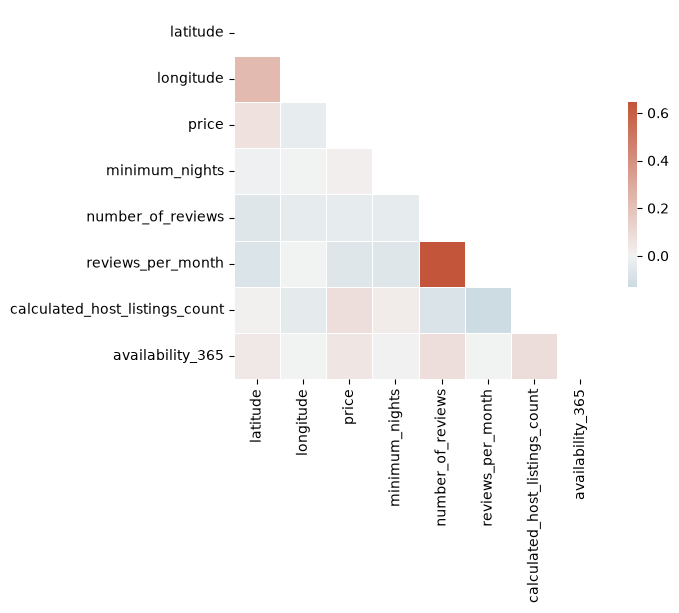

In [18]:
correlation = data.select_dtypes(include="number").corr()
sns.heatmap(
    correlation,
    mask=np.triu(np.ones_like(correlation, dtype=bool)),
    cmap=sns.diverging_palette(230, 20, as_cmap=True),
    center=0,
    square=True,
    linewidths=.5,
    cbar_kws={"shrink": .5}
)

Considerando fuertes las correlaciones iguales o superiores a 0,5 en valor absoluto, solo destaca la relación positiva entre `number_of_reviews` y `reviews_per_month` (0,65). Esto indica que los alojamientos con más reseñas totales tienden a recibir también más reseñas al mes, algo completamente normal, ya que ambas variables están relacionadas con la actividad de las reseñas. El resto de las correlaciones son débiles.

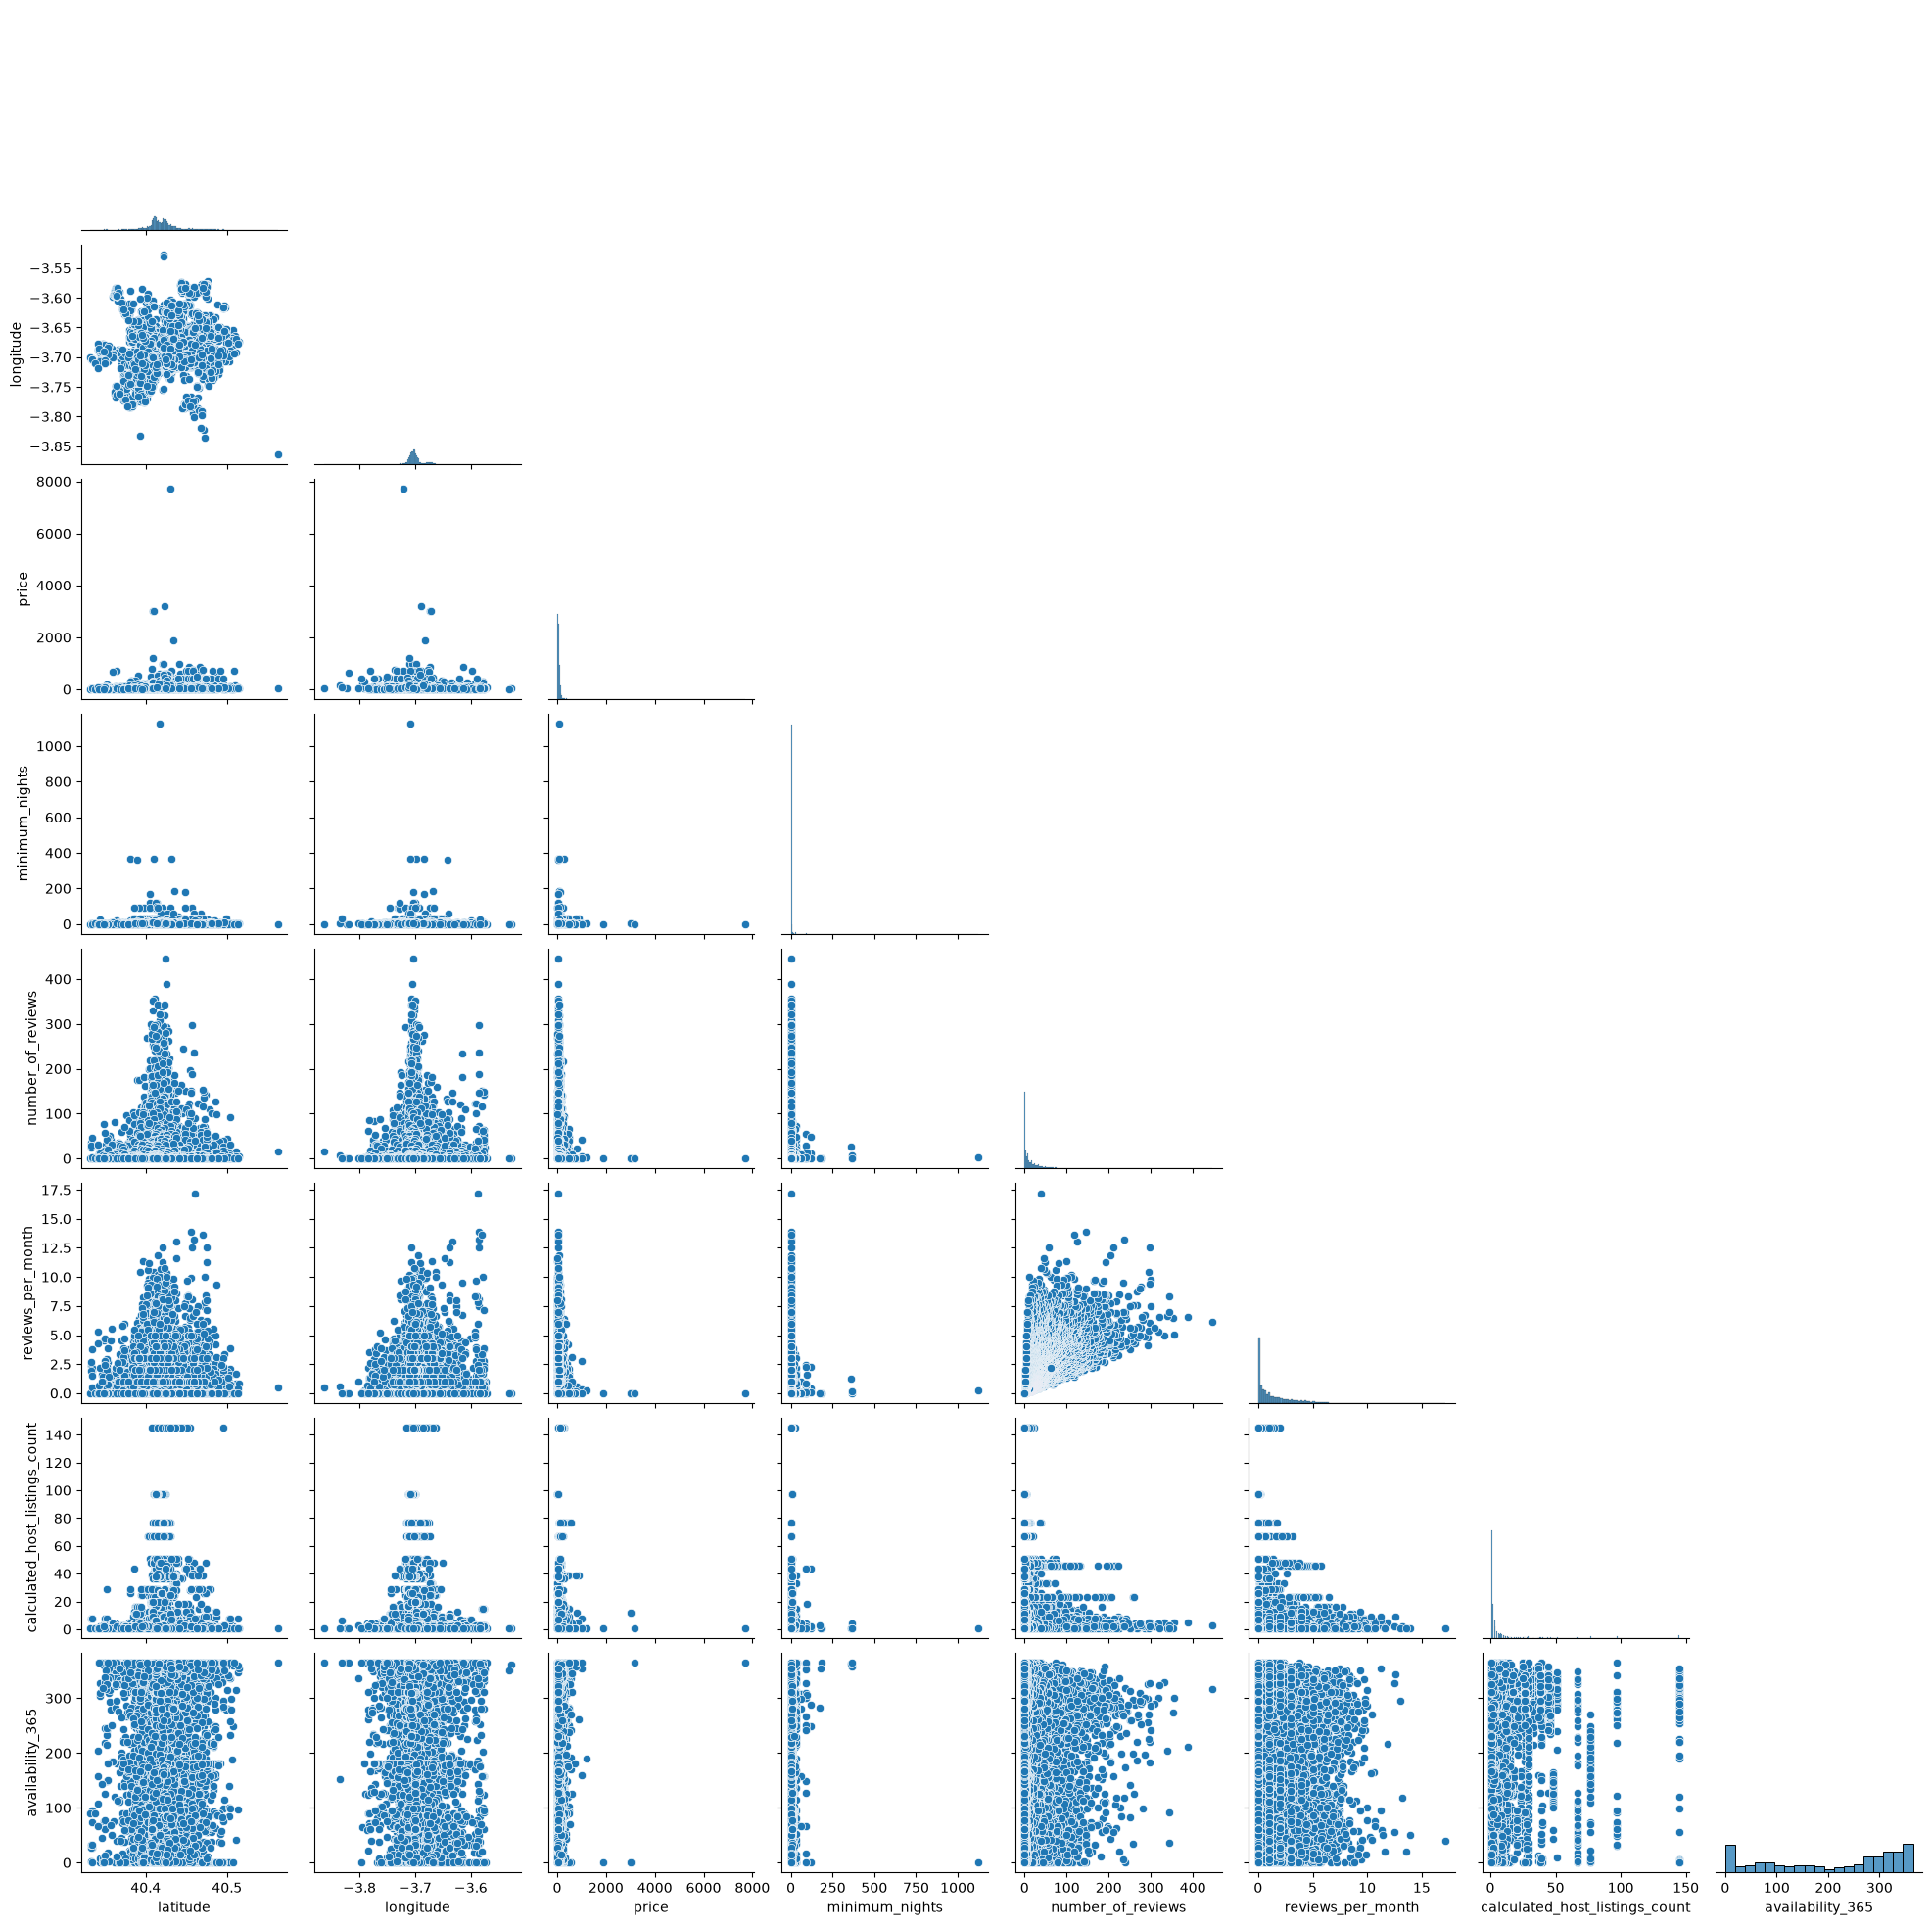

In [19]:
sns.pairplot(data, corner=True)

La matriz de dispersión muestra que no hay tendencias claras en la mayoría de las relaciones entre variables. Destaca la relación positiva entre `number_of_reviews` y `reviews_per_month`, coherente con la correlación observada anteriormente.

<a id="preprocesamiento-de-datos"></a>

### Preprocesamiento de datos

In [20]:
def data_preprocessing_pipeline(data):
    target_variable = "room_type"
    quantitative_variables = data.select_dtypes(include="number").columns.tolist()
    qualitative_variables = data.select_dtypes(include=["object", "str"]).columns.tolist()
    qualitative_variables.remove(target_variable)

    # Outliers
    maximum_price = data["price"].max()
    maximum_minimum_nights = data["minimum_nights"].max()
    transformed_data = data[
        (data["price"] < maximum_price) &
        (data["minimum_nights"] < maximum_minimum_nights)
    ]

    # Training and Testing Dataset Split
    y = transformed_data["room_type"]
    X = transformed_data.drop(columns=["room_type"])
    X_train, X_test, y_train, y_test = train_test_split(
        X,
        y,
        test_size=0.2,
        stratify=y,
        random_state=42
    )
    X_train_numeric = X_train[quantitative_variables]
    X_test_numeric = X_test[quantitative_variables]
    X_train_categorical = X_train[qualitative_variables]
    X_test_categorical = X_test[qualitative_variables]

    # Encoding categorical variables
    encoder = OneHotEncoder(handle_unknown="ignore", sparse_output=False,).set_output(transform="pandas")
    X_train_categorical = encoder.fit_transform(X_train_categorical)
    X_test_categorical = encoder.transform(X_test_categorical)

    X_train = pd.concat([X_train_numeric, X_train_categorical], axis=1)
    X_test = pd.concat([X_test_numeric, X_test_categorical], axis=1)

    # Missing values
    imputer = SimpleImputer(strategy="median").set_output(transform="pandas")
    X_train = imputer.fit_transform(X_train)
    X_test = imputer.transform(X_test)

    # Feature engineering
    X_train["minimum_stay_cost"] = X_train["price"] * X_train["minimum_nights"]
    X_test["minimum_stay_cost"] = X_test["price"] * X_test["minimum_nights"]
    X_train["host_multiple_listings"] = (X_train["calculated_host_listings_count"] > 1).astype(int)
    X_test["host_multiple_listings"] = (X_test["calculated_host_listings_count"] > 1).astype(int)

    # Normalization
    scaler = StandardScaler()
    X_scaled_train = scaler.fit_transform(X_train)
    X_scaled_test = scaler.transform(X_test)

    return X_train, X_scaled_train, X_test, X_scaled_test, y_train, y_test

La función `data_preprocessing_pipeline` organiza el preprocesamiento de los datos en una **pipeline** de cinco etapas.

1. **Valores atípicos**. Los máximos de `price` y `minimum_nights`, correspondientes a 7.700 euros y 1.125 noches, respectivamente, resultan poco razonables en el contexto del alquiler turístico analizado. El filtrado elimina las filas que contienen alguno de estos máximos.

2. **Separación de datos en conjuntos de entrenamiento y test**. La variable objetivo `room_type` queda separada del resto de variables. Tras mezclar los registros aleatoriamente, el 80 % de los datos se destina al entrenamiento y el 20 % al test, que permitirá evaluar el modelo con datos que no ha utilizado para aprender.

   `random_state=42` garantiza la misma división en cada ejecución, siempre que los datos de entrada y su orden no cambien. 
   
   `stratify=y` conserva aproximadamente la proporción de las **clases desbalanceadas** en entrenamiento y test.

   `OneHotEncoder` convierte `neighbourhood_group` y `neighbourhood` en columnas numéricas sin establecer un orden entre sus categorías. `room_type` no requiere codificación porque es la variable objetivo y scikit-learn admite sus etiquetas de texto.

3. **Valores ausentes**. `SimpleImputer(strategy="median")` sustituye los valores ausentes por la mediana de su correspondiente columna. No hace falta una comprobación previa con `data.isnull().values.any()` debido a que el imputador rellena automáticamente los ausentes cuando existen y conserva los demás valores.

4. **Feature Engineering**. La variable `minimum_stay_cost`, calculada como `price * minimum_nights`, representa el coste mínimo de una reserva. Por otro lado, `host_multiple_listings` indica si el anfitrión gestiona más de un anuncio: toma el valor 1 cuando esto ocurre y 0 en caso contrario.

5. **Normalización**. `StandardScaler` pone las variables en una escala comparable para facilitar el aprendizaje del modelo. El árbol de decisión no necesita escalar las variables porque las divisiones dependen del orden de sus valores y, al escalar, cambia el umbral numérico.

In [21]:
X_train, X_scaled_train, X_test, X_scaled_test, y_train, y_test = data_preprocessing_pipeline(data)

print(X_train.shape)
print(X_scaled_train.shape)
print(X_test.shape)
print(X_scaled_test.shape)
print(y_train.shape)
print(y_test.shape)

print(pd.isna(X_train).sum().sum())
print(pd.isna(X_scaled_train).sum().sum())
print(pd.isna(X_test).sum().sum())
print(pd.isna(X_scaled_test).sum().sum())
print(y_train.isna().sum())
print(y_test.isna().sum())

print(X_train.iloc[:5, :8].round(2))
print(pd.DataFrame(X_scaled_train).iloc[:5, :8].round(2))
print(y_train.head())

(10655, 157)
(10655, 157)
(2664, 157)
(2664, 157)
(10655,)
(2664,)
0
0
0
0
0
0
       latitude  longitude  price  minimum_nights  number_of_reviews  \
11145     40.42      -3.70   24.0             1.0                4.0   
3034      40.41      -3.70   69.0             1.0               75.0   
5915      40.44      -3.70   35.0             3.0                0.0   
9451      40.41      -3.70   48.0             3.0               22.0   
10175     40.49      -3.69   39.0             5.0                7.0   

       reviews_per_month  calculated_host_listings_count  availability_365  
11145               1.25                             2.0             353.0  
3034                2.90                            48.0             140.0  
5915                0.00                             8.0             165.0  
9451                3.16                             2.0             324.0  
10175               1.67                             1.0             161.0  
      0     1     2     3 

Tras el preprocesamiento, el conjunto de entrenamiento contiene 10.655 registros y el de test 2.664, ambos sin valores ausentes.

El número de características aumenta hasta 157 porque `OneHotEncoder` crea una columna dummy por cada categoría de las variables cualitativas. Por ejemplo, para un alojamiento en Centro, `neighbourhood_group_Centro` vale 1 y las columnas de los demás distritos valen 0.

<a id="evaluacion-de-modelos"></a>

### Evaluación de modelos

<a id="exactitud"></a>

#### Exactitud (Accuracy)

In [22]:
models_X = [
    (GaussianNB(), X_scaled_train),
    (KNeighborsClassifier(), X_scaled_train),
    (DecisionTreeClassifier(random_state=42), X_train),
]

for model, X in models_X:
    scores = cross_val_score(model, X, y_train, cv=10, scoring="accuracy")
    print(f"{type(model).__name__} {scores.mean():.4f}")

GaussianNB 0.1504
KNeighborsClassifier 0.7777
DecisionTreeClassifier 0.8634


La validación cruzada divide el conjunto de entrenamiento en diez partes y realiza diez rondas (`cv=10`). En cada ronda, el modelo se entrena con nueve partes y se evalúa con la restante. La parte de validación va rotando hasta que todas se han usado una vez. Al final, se calcula la media de los diez valores de accuracy, uno por ronda.

El árbol de decisión obtuvo la mayor exactitud media (86,34 %), seguido de KNN (77,77 %) y Naive Bayes gaussiano (15,04 %).

<a id="matriz-de-confusion"></a>

#### Matriz de confusión

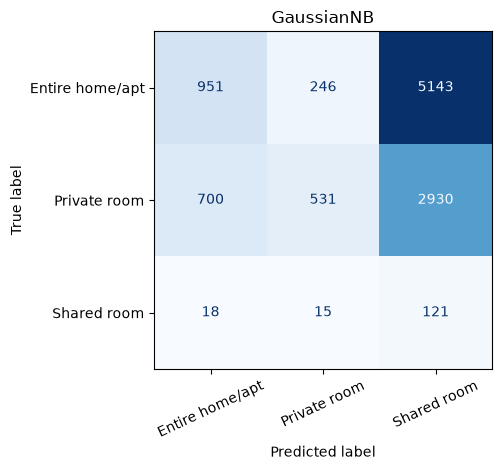

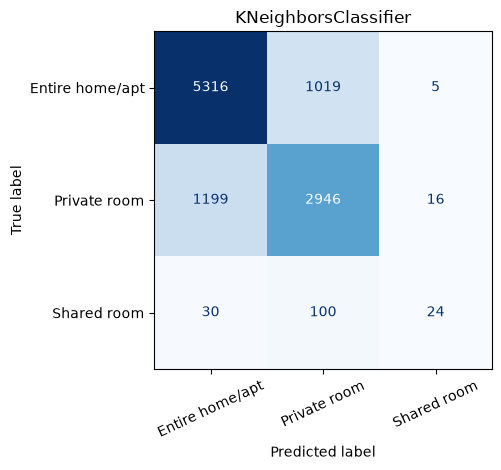

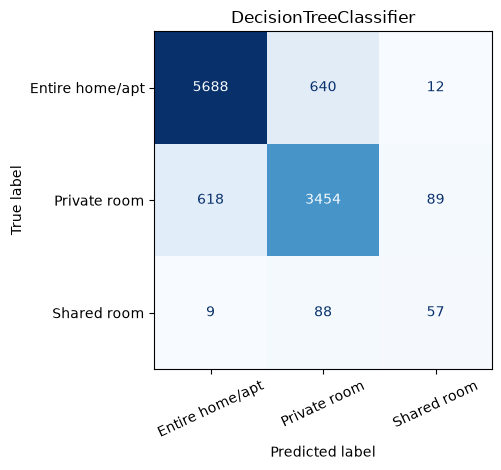

In [23]:
for model, X in models_X:
    y_pred = cross_val_predict(model, X, y_train, cv=10)

    ConfusionMatrixDisplay.from_predictions(
        y_train,
        y_pred,
        cmap="Blues",
        xticks_rotation=25,
        colorbar=False,
    )
    plt.title(type(model).__name__)
    plt.tight_layout()

Las matrices de confusión complementan el accuracy porque muestran qué clases acierta y cuáles confunde cada modelo. Las filas representan las clases reales y las columnas, las predichas. Los aciertos aparecen en la diagonal. Por ejemplo, de las 154 `Shared room`, el árbol identificó correctamente 57, clasificó 88 como `Private room` y 9 como `Entire home/apt`.

En general, el árbol de decisión concentra más aciertos en la diagonal. KNN y el árbol confunden sobre todo `Entire home/apt` con `Private room` y tienen dificultades para reconocer `Shared room`.

El árbol de decisión obtuvo la mayor exactitud (86,34 %) y reconoció más habitaciones compartidas que KNN, que acertó 24. Naive Bayes identificó 121 `Shared room`, pero asignó esa misma etiqueta a más de 8.000 alojamientos de otras clases. Esto explica que, pese a detectar más `Shared room`, obtuviera la menor exactitud global (15,04 %).

<a id="afinacion-de-hiperparametros"></a>

### Afinación de hiperparámetros

In [24]:
knn_grid_search = GridSearchCV(
    KNeighborsClassifier(),
    {
        "n_neighbors": [3, 5, 7, 9, 11, 13],
    },
    cv=10,
    scoring="accuracy",
)
knn_grid_search.fit(X_scaled_train, y_train)

decision_tree_grid_search = GridSearchCV(
    DecisionTreeClassifier(random_state=42),
    {
        "max_leaf_nodes": np.arange(2, 51),
        "min_samples_split": np.arange(2, 7),
        "max_depth": np.arange(1, 21),
    },
    cv=10,
    scoring="accuracy",
)
decision_tree_grid_search.fit(X_train, y_train)

best_decision_tree_estimator = decision_tree_grid_search.best_estimator_

print(f"KNN {knn_grid_search.best_params_} {knn_grid_search.best_score_}")
print(f"Decision tree {decision_tree_grid_search.best_params_} {decision_tree_grid_search.best_score_}")

KNN {'n_neighbors': 3} 0.7787918505403907
Decision tree {'max_depth': np.int64(7), 'max_leaf_nodes': np.int64(48), 'min_samples_split': np.int64(2)} 0.8931021148781368


`GridSearchCV` evalúa cada combinación de hiperparámetros mediante validación cruzada de diez rondas y selecciona la que obtiene el mayor accuracy medio. Naive Bayes gaussiano queda fuera de la búsqueda porque se evalúa con sus parámetros por defecto.

En KNN, el mejor resultado fue del 77,88 % con 3 vecinos, apenas por encima del 77,77 % inicial. El árbol de decisión pasó del 86,34 % al 89,31 % con una profundidad máxima de 7, un límite de 48 hojas y un mínimo de 2 registros para dividir un nodo.

[Text(0.4441793893129771, 0.9375, 'price <= 40.5\ngini = 0.493\nsamples = 10655\nvalue = [6340, 4161, 154]\nclass = Entire home/apt'),
 Text(0.16412213740458015, 0.8125, 'price <= 35.5\ngini = 0.25\nsamples = 3894\nvalue = [413, 3343, 138]\nclass = Private room'),
 Text(0.30415076335877866, 0.875, 'True  '),
 Text(0.07633587786259542, 0.6875, 'minimum_stay_cost <= 13.5\ngini = 0.186\nsamples = 3260\nvalue = [193, 2932, 135]\nclass = Private room'),
 Text(0.04580152671755725, 0.5625, 'calculated_host_listings_count <= 2.5\ngini = 0.483\nsamples = 59\nvalue = [0, 24, 35]\nclass = Shared room'),
 Text(0.030534351145038167, 0.4375, 'latitude <= 40.385\ngini = 0.383\nsamples = 31\nvalue = [0, 23, 8]\nclass = Private room'),
 Text(0.015267175572519083, 0.3125, 'gini = 0.408\nsamples = 7\nvalue = [0, 2, 5]\nclass = Shared room'),
 Text(0.04580152671755725, 0.3125, 'gini = 0.219\nsamples = 24\nvalue = [0, 21, 3]\nclass = Private room'),
 Text(0.061068702290076333, 0.4375, 'gini = 0.069\nsample

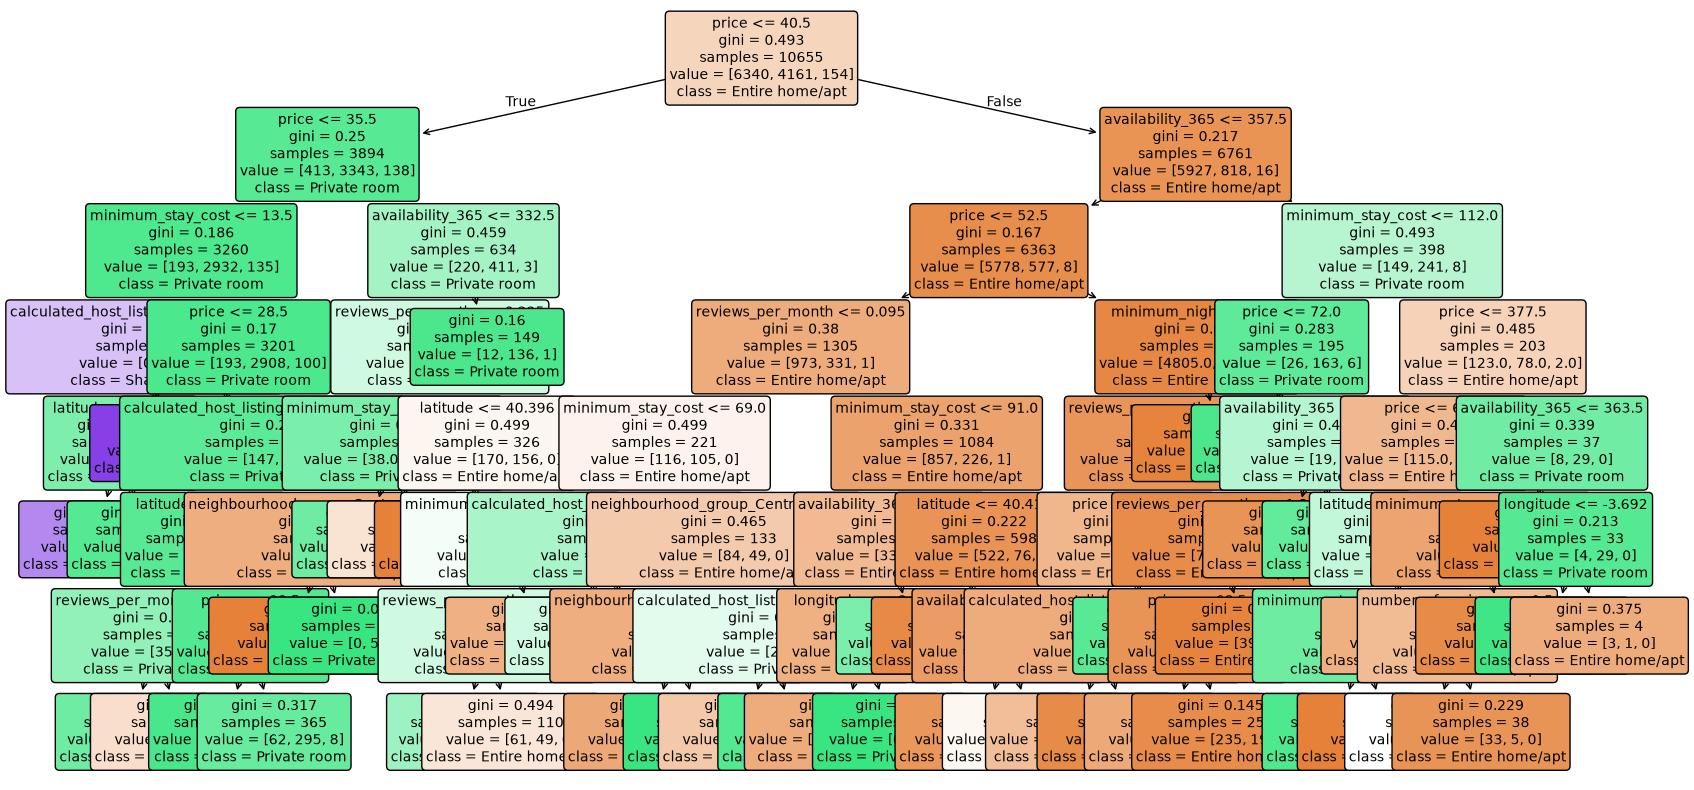

In [26]:
plt.figure(figsize=(20, 10))
plot_tree(
    best_decision_tree_estimator,
    filled=True,
    rounded=True,
    class_names=best_decision_tree_estimator.classes_.tolist(),
    feature_names=X_train.columns.tolist(),
    fontsize=10
)

El árbol hace la primera división según `Price`. En la rama de 40,50 € o menos predominan `Private room` y, en la de precios superiores, `Entire home/apt`. Las siguientes divisiones tienen en cuenta variables como `availability_365` y `minimum_stay_cost`.

En el nodo inicial, `samples = 10655` indica el total de registros y `value = [6340, 4161, 154]` muestra cómo se reparten entre las clases. Hay 6.340 `Entire home/apt`, 4.161 `Private room` y 154 `Shared room`. Por eso, `class` muestra `Entire home/apt`, la clase más frecuente del nodo.

El índice de Gini mide cuánto se mezclan las clases. Para calcularlo, se elevan al cuadrado las proporciones de cada clase y se resta su suma de 1.

`Gini = 1 − [(6340 / 10655)² + (4161 / 10655)² + (154 / 10655)²] ≈ 0,493`

Si todos los registros del nodo pertenecen a una sola clase, el índice vale 0.

<a id="conclusiones"></a>

### Conclusiones

In [28]:
gaussian_naive_bayes = GaussianNB()
gaussian_naive_bayes.fit(X_scaled_train, y_train)

print(f"Gaussian Naive Bayes {gaussian_naive_bayes.score(X_scaled_test, y_test):.2%}")
print(f"KNN {knn_grid_search.score(X_scaled_test, y_test):.2%}")
print(f"Decision tree {decision_tree_grid_search.score(X_test, y_test):.2%}")

Gaussian Naive Bayes 13.96%
KNN 78.15%
Decision tree 89.68%


La validación cruzada y la búsqueda de hiperparámetros se realizaron con el conjunto de entrenamiento. El conjunto de test, formado por 2.664 registros, quedó reservado para la evaluación final.

Para KNN y el árbol de decisión, usamos `.score()` para calcular la exactitud en test porque `GridSearchCV` ya ha entrenado cada modelo con sus mejores hiperparámetros y todos los datos de entrenamiento. Naive Bayes gaussiano se entrena aparte con sus parámetros por defecto.

El **árbol de decisión** obtuvo la mayor exactitud en test (**89,68 %**), seguido de **KNN** (**78,15 %**) y **Naive Bayes gaussiano** (**13,96 %**). El orden coincide con el de la validación cruzada. El árbol fue el mejor de los tres en exactitud global, aunque las matrices de confusión de la validación cruzada muestran que también tuvo dificultades para reconocer `Shared room`, la clase minoritaria.

He aprovechado este proyecto para aprender lo máximo posible y entender el motivo de cada paso. Por eso, quizás he explicado el proceso con más detalle del necesario en algunos apartados.